# **Online Store Sales Data Analytics**

## **Objective**


### Analyze an online store sales dataset using Python and generate business insights through data cleaning, processing, analysis, and visualization.



## **Part 1 — Data Loading**


### Import required libraries


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

### Load the CSV dataset using Pandas


In [7]:
df = pd.read_excel("sales_data_2000_rows.xlsx")

### Display first 5 rows


In [9]:
df.head(5)

,Order_ID,Date,Product,Category,City,Quantity,Price
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624


### Check dataset information


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  2000 non-null   int64  
 1   Date      2000 non-null   str    
 2   Product   2000 non-null   str    
 3   Category  2000 non-null   str    
 4   City      2000 non-null   str    
 5   Quantity  1999 non-null   float64
 6   Price     2000 non-null   int64  
dtypes: float64(1), int64(2), str(4)
memory usage: 109.5 KB


In [11]:
df.describe()

,Order_ID,Quantity,Price
count,2000.000000,1999.000000,2000.00000
mean,2000.500000,3.036018,8293.60150
std,577.494589,1.415877,14462.36937
min,1001.000000,1.000000,-73.00000
25%,1500.750000,2.000000,495.75000
50%,2000.500000,3.000000,1487.00000
75%,2500.250000,4.000000,8765.50000
max,3000.000000,5.000000,55297.00000


## **Part 2 — Data Cleaning**

### Data cleaning is the process of identifying and correcting missing values, duplicate records, spelling inconsistencies, and incorrect data types to improve data quality before analysis.

### Check missing values


In [13]:
df.isnull().sum()

Order_ID    0
Date        0
Product     0
Category    0
City        0
Quantity    1
Price       0
dtype: int64

### Remove duplicate records


In [14]:
df.duplicated().sum()

np.int64(0)

### Correct spelling mistakes if any


In [15]:
print("Products:", df["Product"].unique())
print("Categories:", df["Category"].unique())
print("Cities:", df["City"].unique())

Products: <StringArray>
[ 'Printer',      'Pen',    'Mouse',    'Chair', 'Notebook',    'Table',
   'Laptop',      'Bag', 'Keyboard',     'Sofa',  'Monitor',   'Bottle']
Length: 12, dtype: str
Categories: <StringArray>
['Electronics', 'Stationery', 'Furniture', 'Accessories']
Length: 4, dtype: str
Cities: <StringArray>
[  'Kolkata', 'Hyderabad',   'Chennai', 'Ahmedabad',    'Mumbai',      'Pune',
 'Bangalore',     'Delhi']
Length: 8, dtype: str


In [16]:
df["Product"] = df["Product"].str.strip().str.title()
df["Category"] = df["Category"].str.strip().str.title()
df["City"] = df["City"].str.strip().str.title()

In [19]:
print(df["Date"].dtype)

datetime64[us]


### Convert Date column into datetime format


In [18]:
df["Date"] = pd.to_datetime(df["Date"])

In [20]:
df["Date"].isnull().sum()

np.int64(0)

In [23]:
df[df.isnull().any(axis=1)]

,Order_ID,Date,Product,Category,City,Quantity,Price


In [22]:
median_quantity = df["Quantity"].median()

df["Quantity"] = df["Quantity"].fillna(median_quantity)

## **Part 3 — Data Processing**

### In this section, I will create a new column named Revenue by multiplying Quantity by Price for each sales record. This column will help measure the revenue generated by individual transactions and support further business analysis.

### Create a new column:


In [26]:
df["Revenue"] = df["Quantity"] * df["Price"]

In [27]:
df.head(4)

,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591,28773.0
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318,1590.0
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697,697.0
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410,3410.0


In [28]:
print(df.columns)

Index(['Order_ID', 'Date', 'Product', 'Category', 'City', 'Quantity', 'Price',
       'Revenue'],
      dtype='str')


In [29]:
print(df["Revenue"].dtype)

float64


In [30]:
print("Total Revenue:", df["Revenue"].sum())

Total Revenue: 51501934.0


In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Order_ID  2000 non-null   int64         
 1   Date      2000 non-null   datetime64[us]
 2   Product   2000 non-null   str           
 3   Category  2000 non-null   str           
 4   City      2000 non-null   str           
 5   Quantity  2000 non-null   float64       
 6   Price     2000 non-null   int64         
 7   Revenue   2000 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(2), str(3)
memory usage: 125.1 KB


In [32]:
df.isnull().sum()

Order_ID    0
Date        0
Product     0
Category    0
City        0
Quantity    0
Price       0
Revenue     0
dtype: int64

In [33]:
df.to_csv("cleaned_sales_data.csv", index=False)

In [34]:
import os

print(os.path.exists("cleaned_sales_data.csv"))

True


In [10]:
cleaned_df = pd.read_csv("cleaned_sales_data.csv")

cleaned_df.head()

,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591,28773.0
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318,1590.0
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697,697.0
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410,3410.0
4,1005,2025-04-12,Mouse,Electronics,Mumbai,3.0,624,1872.0


In [37]:
cleaned_df.columns

Index(['Order_ID', 'Date', 'Product', 'Category', 'City', 'Quantity', 'Price',
       'Revenue'],
      dtype='str')

## **Part 4 — Data Analysis**


## Task 1 — Total Revenue


In [38]:
total_revenue = df["Revenue"].sum()

print("Total Revenue:", total_revenue)

Total Revenue: 51501934.0


## **Task 2 — Best-Selling Product**

In [39]:
product_sales = df.groupby("Product")["Quantity"].sum()

product_sales = product_sales.sort_values(ascending=False)

print(product_sales)

Product
Chair       568.0
Sofa        537.0
Notebook    531.0
Bag         529.0
Printer     517.0
Keyboard    509.0
Pen         507.0
Bottle      497.0
Laptop      492.0
Monitor     476.0
Mouse       460.0
Table       449.0
Name: Quantity, dtype: float64


In [40]:
print(product_sales.head(1))

Product
Chair    568.0
Name: Quantity, dtype: float64


## **Task 3 — Best-Performing City**

In [41]:
city_revenue = df.groupby("City")["Revenue"].sum()

city_revenue = city_revenue.sort_values(ascending=False)

print(city_revenue)

City
Ahmedabad    7449911.0
Delhi        7092644.0
Kolkata      6819173.0
Mumbai       6704675.0
Hyderabad    6565333.0
Chennai      5944069.0
Pune         5764738.0
Bangalore    5161391.0
Name: Revenue, dtype: float64


## **Task 4 — Category Analysis&**

In [43]:
category_revenue = df.groupby("Category")["Revenue"].sum()

category_revenue = category_revenue.sort_values(ascending=False)

print(category_revenue)

Category
Electronics    37095222.0
Furniture      13343784.0
Accessories      905769.0
Stationery       157159.0
Name: Revenue, dtype: float64


## **Task 5 — Monthly Sales Analysis**

In [44]:
df["YearMonth"] = df["Date"].dt.to_period("M")

In [45]:
df.head(2)

,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue,YearMonth
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591,28773.0,2025-02
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318,1590.0,2025-08


In [46]:
monthly_sales = df.groupby("YearMonth")["Revenue"].sum()

print(monthly_sales)

YearMonth
2025-01    4021909.0
2025-02    3655339.0
2025-03    4607846.0
2025-04    4785474.0
2025-05    4884091.0
2025-06    3654206.0
2025-07    3979183.0
2025-08    4012286.0
2025-09    4318017.0
2025-10    4428577.0
2025-11    4185989.0
2025-12    4891185.0
2026-01      77832.0
Freq: M, Name: Revenue, dtype: float64


## **Part 5 — Data Visualization**

## Task 1 — Bar Chart: Revenue by City

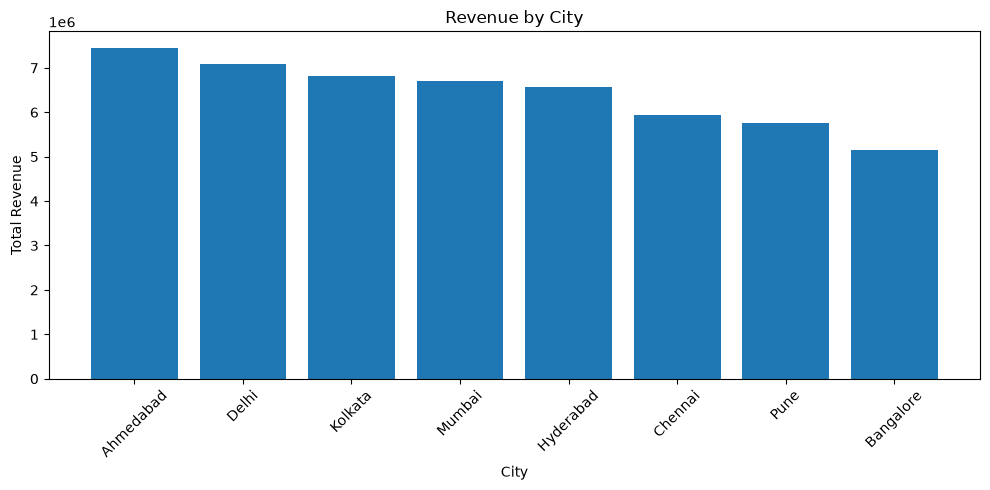

In [47]:
city_revenue = df.groupby("City")["Revenue"].sum()
city_revenue = city_revenue.sort_values(ascending=False)

plt.figure(figsize=(10, 5))

plt.bar(city_revenue.index, city_revenue.values)

plt.title("Revenue by City")
plt.xlabel("City")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## Task 2 — Pie Chart: Category Contribution

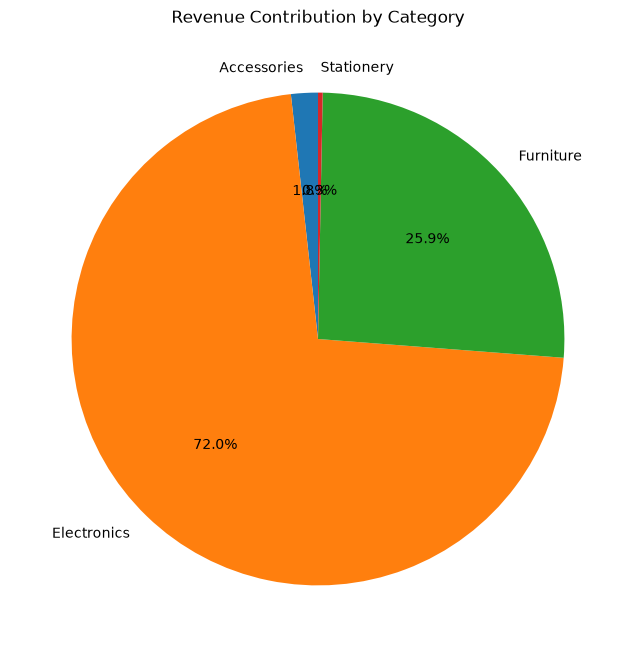

In [48]:
category_revenue = df.groupby("Category")["Revenue"].sum()

plt.figure(figsize=(8, 8))

plt.pie(
    category_revenue,
    labels=category_revenue.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Contribution by Category")

plt.show()

## Task 3 — Line Chart: Monthly Sales Trend

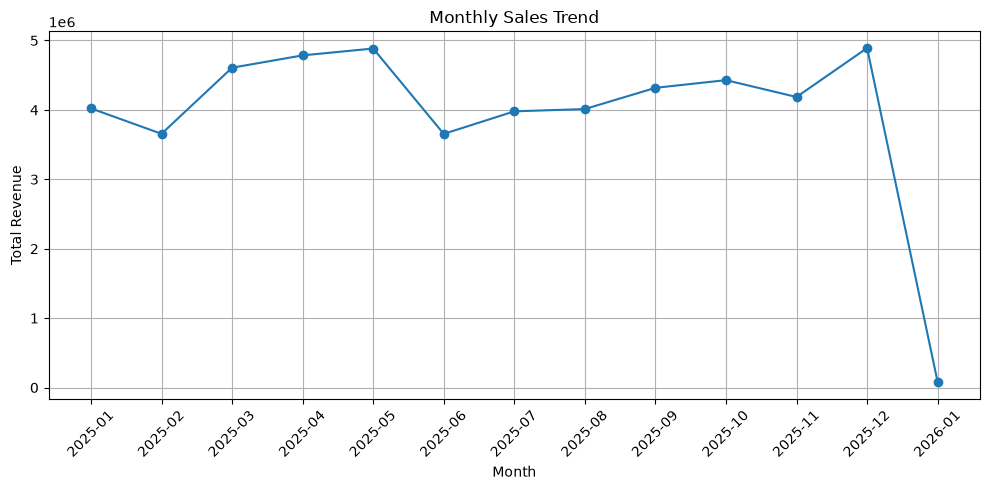

In [51]:
plt.figure(figsize=(10, 5))

plt.plot(
    month_revenue.index.astype(str),
    month_revenue.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [52]:
df.describe()

,Order_ID,Date,Quantity,Price,Revenue
count,2000.000000,2000,2000.000000,2000.00000,2000.000000
mean,2000.500000,2025-07-01 04:22:04.800000,3.036000,8293.60150,25750.967000
min,1001.000000,2025-01-01 00:00:00,1.000000,-73.00000,-360.000000
25%,1500.750000,2025-03-31 00:00:00,2.000000,495.75000,1242.750000
50%,2000.500000,2025-07-01 00:00:00,3.000000,1487.00000,5998.000000
75%,2500.250000,2025-10-01 00:00:00,4.000000,8765.50000,28699.500000
max,3000.000000,2026-01-01 00:00:00,5.000000,55297.00000,276360.000000
std,577.494589,NaN,1.415523,14462.36937,50843.406045


In [53]:
df[df["Price"] < 0]

,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue,YearMonth
46,1047,2025-12-02,Pen,Stationery,Bangalore,2.0,-44,-88.0,2025-12
91,1092,2025-03-28,Notebook,Stationery,Ahmedabad,3.0,-11,-33.0,2025-03
105,1106,2025-04-26,Notebook,Stationery,Delhi,5.0,-6,-30.0,2025-04
170,1171,2025-10-28,Pen,Stationery,Mumbai,4.0,-21,-84.0,2025-10
329,1330,2025-08-13,Pen,Stationery,Mumbai,3.0,-22,-66.0,2025-08
337,1338,2025-11-16,Pen,Stationery,Pune,3.0,-31,-93.0,2025-11
365,1366,2025-04-09,Pen,Stationery,Kolkata,3.0,-12,-36.0,2025-04
367,1368,2025-02-24,Pen,Stationery,Ahmedabad,2.0,-56,-112.0,2025-02
405,1406,2025-06-01,Notebook,Stationery,Kolkata,4.0,-4,-16.0,2025-06
422,1423,2025-03-17,Pen,Stationery,Mumbai,2.0,-59,-118.0,2025-03


In [54]:
df[(df["Price"] < 0) | (df["Quantity"] < 0)]

,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue,YearMonth
46,1047,2025-12-02,Pen,Stationery,Bangalore,2.0,-44,-88.0,2025-12
91,1092,2025-03-28,Notebook,Stationery,Ahmedabad,3.0,-11,-33.0,2025-03
105,1106,2025-04-26,Notebook,Stationery,Delhi,5.0,-6,-30.0,2025-04
170,1171,2025-10-28,Pen,Stationery,Mumbai,4.0,-21,-84.0,2025-10
329,1330,2025-08-13,Pen,Stationery,Mumbai,3.0,-22,-66.0,2025-08
337,1338,2025-11-16,Pen,Stationery,Pune,3.0,-31,-93.0,2025-11
365,1366,2025-04-09,Pen,Stationery,Kolkata,3.0,-12,-36.0,2025-04
367,1368,2025-02-24,Pen,Stationery,Ahmedabad,2.0,-56,-112.0,2025-02
405,1406,2025-06-01,Notebook,Stationery,Kolkata,4.0,-4,-16.0,2025-06
422,1423,2025-03-17,Pen,Stationery,Mumbai,2.0,-59,-118.0,2025-03


In [55]:
df[df["Price"] < 0].shape[0]

42

In [56]:
import numpy as np

df.loc[df["Price"] < 0, "Price"] = np.nan

In [60]:
df.isnull().sum()

Order_ID     0
Date         0
Product      0
Category     0
City         0
Quantity     0
Price        0
Revenue      0
YearMonth    0
dtype: int64

In [59]:
df["Price"]=df["Price"].fillna(0)

In [61]:
df.head(4)

,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue,YearMonth
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591.0,28773.0,2025-02
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318.0,1590.0,2025-08
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697.0,697.0,2025-07
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410.0,3410.0,2025-08


In [63]:
df["Revenue"] = df["Quantity"] * df["Price"]

In [64]:
df[df["Revenue"]<0]

,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue,YearMonth


## **Part 6: Business Insights**

### Overall Revenue: The store made a total revenue of ₹ 51501934.0 from its sales.

### Best-Selling Product: Chair was the best-selling product, with 568 units sold.

### City Performance: Ahmedabad generated the highest sales revenue, with ₹74,49,911.

### Top 3 Products by Revenue: Laptop – ₹2,71,05,144 , Sofa – ₹81,06,368 , Printer – ₹49,66,315

### Average Quantity per Order: On average, customers purchased 3.04 items per order.

### Category Performance: Electronics generated the highest revenue among all categories, contributing ₹3,70,95,222.

### Lowest City Revenue: Bangalore generated the lowest revenue among the cities, with ₹51,61,391.

### Average Order Value: The average revenue per order was approximately ₹25,751.

## **Part 7 — Recommendations**

## Maintain sufficient stock of Chairs because they have the highest sales quantity.

## Focus on Ahmedabad because it generates the highest revenue.

## Promote Laptop, Sofa, and Printer because they generate the most revenue.

## Use special offers and promotions to increase sales in Bangalore, which has the lowest revenue.

## Introduce combo offers and discounts to encourage customers to buy more items per order.